# Telecom Churn – Exploratory Data Analysis
Dataset: `telecom_churn_dataset.csv` (50,000 customers, 34 columns)

In [4]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
%matplotlib inline

## 1. Load & overview

In [7]:
from pathlib import Path
csv_path = Path("../src/data/raw/telecom_churn_dataset.csv")
df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

Shape: (50000, 34)


,customer_id,gender,age,senior_citizen,state,city_tier,tenure_months,contract_type,plan_type,data_plan,international_plan,voicemail_plan,multiple_lines,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,data_usage_gb,total_day_minutes,total_eve_minutes,total_night_minutes,total_intl_minutes,total_day_calls,total_eve_calls,total_night_calls,total_intl_calls,customer_service_calls,monthly_charges,total_charges,payment_method,paperless_billing,churn
0,CUST-000001,Male,26,0,Andhra Pradesh,Tier 3,19,Month-to-Month,Postpaid,1 GB,Yes,Yes,Yes,Yes,No,No,No,Yes,Yes,0.33,382.8,277.6,231.0,40.2,14,5,21,6,1,1168.44,22132.63,Net Banking,Yes,No
1,CUST-000002,Female,53,0,Tamil Nadu,Tier 1,61,One Year,Prepaid,5 GB,Yes,Yes,No,Yes,No,Yes,No,No Internet Service,Yes,3.71,38.4,159.7,14.3,28.0,82,49,54,10,5,726.35,44364.05,Debit Card,No,No
2,CUST-000003,Female,23,0,Rajasthan,Tier 3,28,One Year,Postpaid,5 GB,No,No,No Phone Service,No,No,No,No,No Internet Service,No,5.01,292.4,205.7,253.1,8.6,17,83,88,4,1,430.73,12100.16,Net Banking,Yes,No
3,CUST-000004,Female,41,0,Karnataka,Tier 2,56,Month-to-Month,Prepaid,2 GB,No,No,No,Yes,No,No Internet Service,Yes,No,No Internet Service,1.78,39.6,204.2,111.5,7.6,3,72,75,11,6,592.51,33121.13,Net Banking,Yes,No
4,CUST-000005,Male,43,0,Kerala,Tier 3,1,Two Year,Postpaid,No Data Plan,No,Yes,Yes,No,Yes,No,No,No,Yes,0.20,91.1,132.2,194.2,0.2,3,0,63,8,2,803.61,767.07,Net Banking,Yes,No


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             50000 non-null  str    
 1   gender                  50000 non-null  str    
 2   age                     50000 non-null  int64  
 3   senior_citizen          50000 non-null  int64  
 4   state                   50000 non-null  str    
 5   city_tier               50000 non-null  str    
 6   tenure_months           50000 non-null  int64  
 7   contract_type           50000 non-null  str    
 8   plan_type               50000 non-null  str    
 9   data_plan               50000 non-null  str    
 10  international_plan      50000 non-null  str    
 11  voicemail_plan          50000 non-null  str    
 12  multiple_lines          50000 non-null  str    
 13  online_security         50000 non-null  str    
 14  online_backup           50000 non-null  str    
 

In [9]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer_ids:", df["customer_id"].duplicated().sum())
print("Total missing values:", df.isna().sum().sum())

Duplicate rows: 0
Duplicate customer_ids: 0
Total missing values: 0


In [10]:
df["churn_flag"] = (df["churn"] == "Yes").astype(int)

num_cols = df.select_dtypes(include="number").columns.drop(["churn_flag", "senior_citizen"]).tolist()
cat_cols = [c for c in df.select_dtypes(exclude="number").columns
            if c not in ("customer_id", "churn")] + ["senior_citizen"]

print("Numeric:", num_cols)
print("Categorical:", cat_cols)

Numeric: ['age', 'tenure_months', 'data_usage_gb', 'total_day_minutes', 'total_eve_minutes', 'total_night_minutes', 'total_intl_minutes', 'total_day_calls', 'total_eve_calls', 'total_night_calls', 'total_intl_calls', 'customer_service_calls', 'monthly_charges', 'total_charges']
Categorical: ['gender', 'state', 'city_tier', 'contract_type', 'plan_type', 'data_plan', 'international_plan', 'voicemail_plan', 'multiple_lines', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'payment_method', 'paperless_billing', 'senior_citizen']


In [11]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,50000.0,46.536000,16.658451,18.00,32.0000,47.000,61.0000,75.00
tenure_months,50000.0,36.409360,20.777430,1.00,18.0000,36.000,54.0000,72.00
data_usage_gb,50000.0,5.234166,7.972320,0.00,0.9000,2.020,4.9700,35.00
total_day_minutes,50000.0,200.865686,115.285594,0.00,100.8000,202.100,301.0000,400.00
total_eve_minutes,50000.0,175.100128,101.133348,0.00,87.5000,175.500,262.6000,350.00
total_night_minutes,50000.0,150.600006,86.660405,0.00,75.7000,151.000,225.6000,300.00
total_intl_minutes,50000.0,9.486040,12.313675,0.00,2.9000,5.900,8.9000,60.00
total_day_calls,50000.0,74.806020,43.603359,0.00,37.0000,75.000,113.0000,150.00
total_eve_calls,50000.0,59.273520,34.643773,0.00,29.0000,59.000,89.0000,119.00
total_night_calls,50000.0,49.343280,28.811268,0.00,24.0000,49.000,74.0000,99.00


## 2. Target distribution

Churn rate: 27.00%


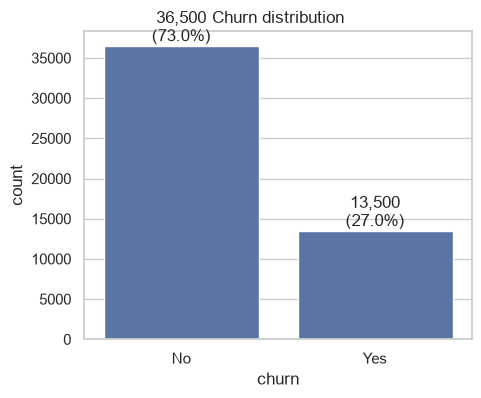

In [12]:
churn_rate = df["churn_flag"].mean()
print(f"Churn rate: {churn_rate:.2%}")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="churn", ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f}\n({p.get_height()/len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Churn distribution")
plt.show()

## 3. Data quality checks

In [13]:
# total_charges should be roughly tenure * monthly_charges
df["charge_gap"] = df["total_charges"] - df["tenure_months"] * df["monthly_charges"]
df["charge_gap"].describe()

count    50000.000000
mean        -0.133172
std         49.849097
min       -198.710000
25%        -33.840000
50%         -0.145000
75%         33.440000
max        213.610000
Name: charge_gap, dtype: float64

In [14]:
# 'No Internet Service' should be consistent with data_plan
pd.crosstab(df["data_plan"], df["online_security"])

online_security,No,No Internet Service,Yes
data_plan,,,
1 GB,5807,1398,2818
2 GB,7206,1723,3457
5 GB,7366,1783,3517
No Data Plan,2866,706,1431
Unlimited,5724,1393,2805


In [15]:
# IQR outlier counts
out = {}
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    out[c] = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
pd.Series(out).sort_values(ascending=False).to_frame("outliers")

,outliers
data_usage_gb,7161
total_intl_minutes,6267
total_charges,241
monthly_charges,159
tenure_months,0
age,0
total_night_minutes,0
total_eve_minutes,0
total_day_minutes,0
total_day_calls,0


## 4. Univariate analysis – numeric

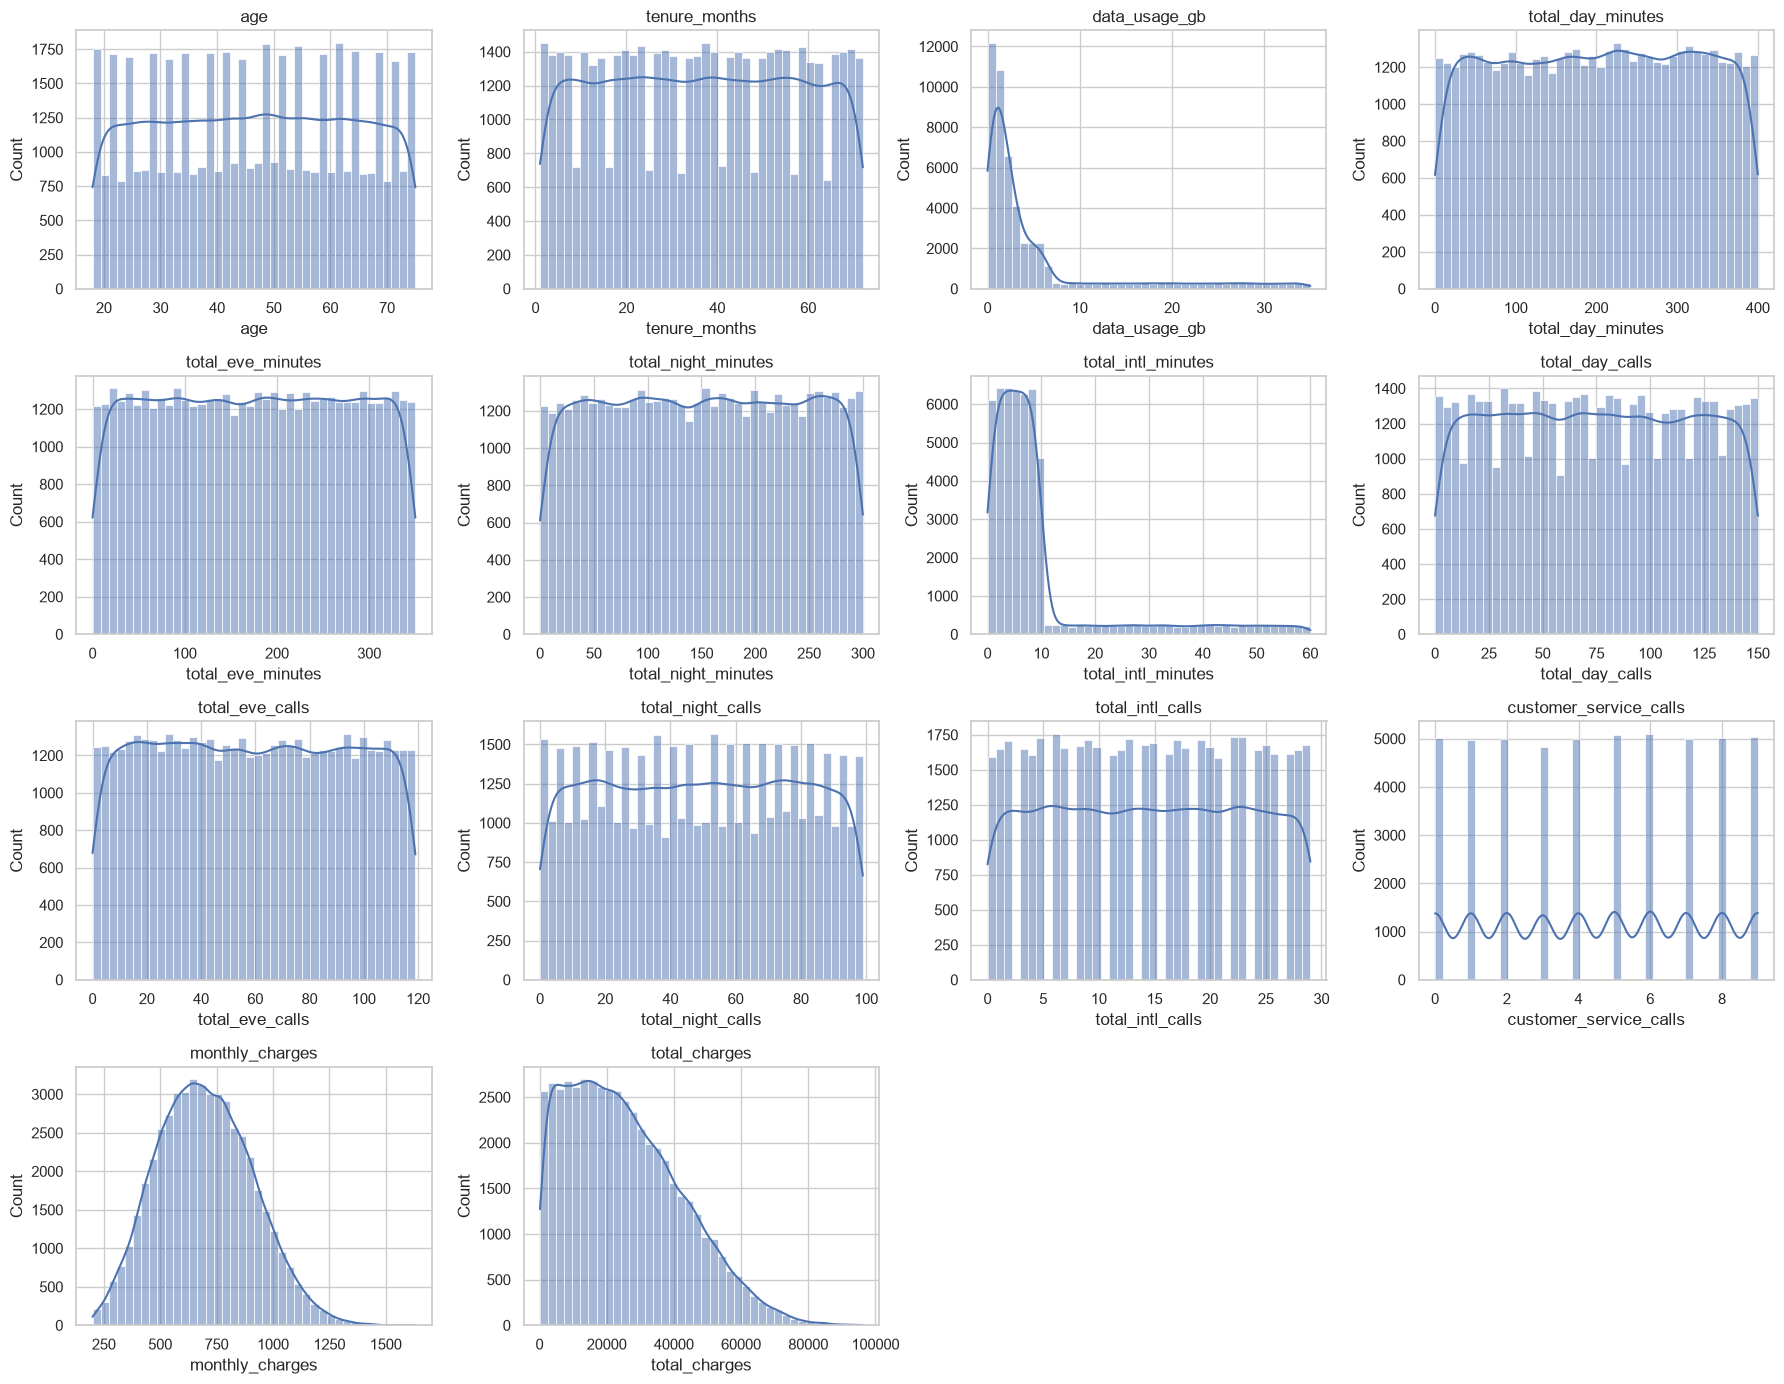

In [16]:
ncols = 4
nrows = int(np.ceil(len(num_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.5 * nrows))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, bins=40, ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

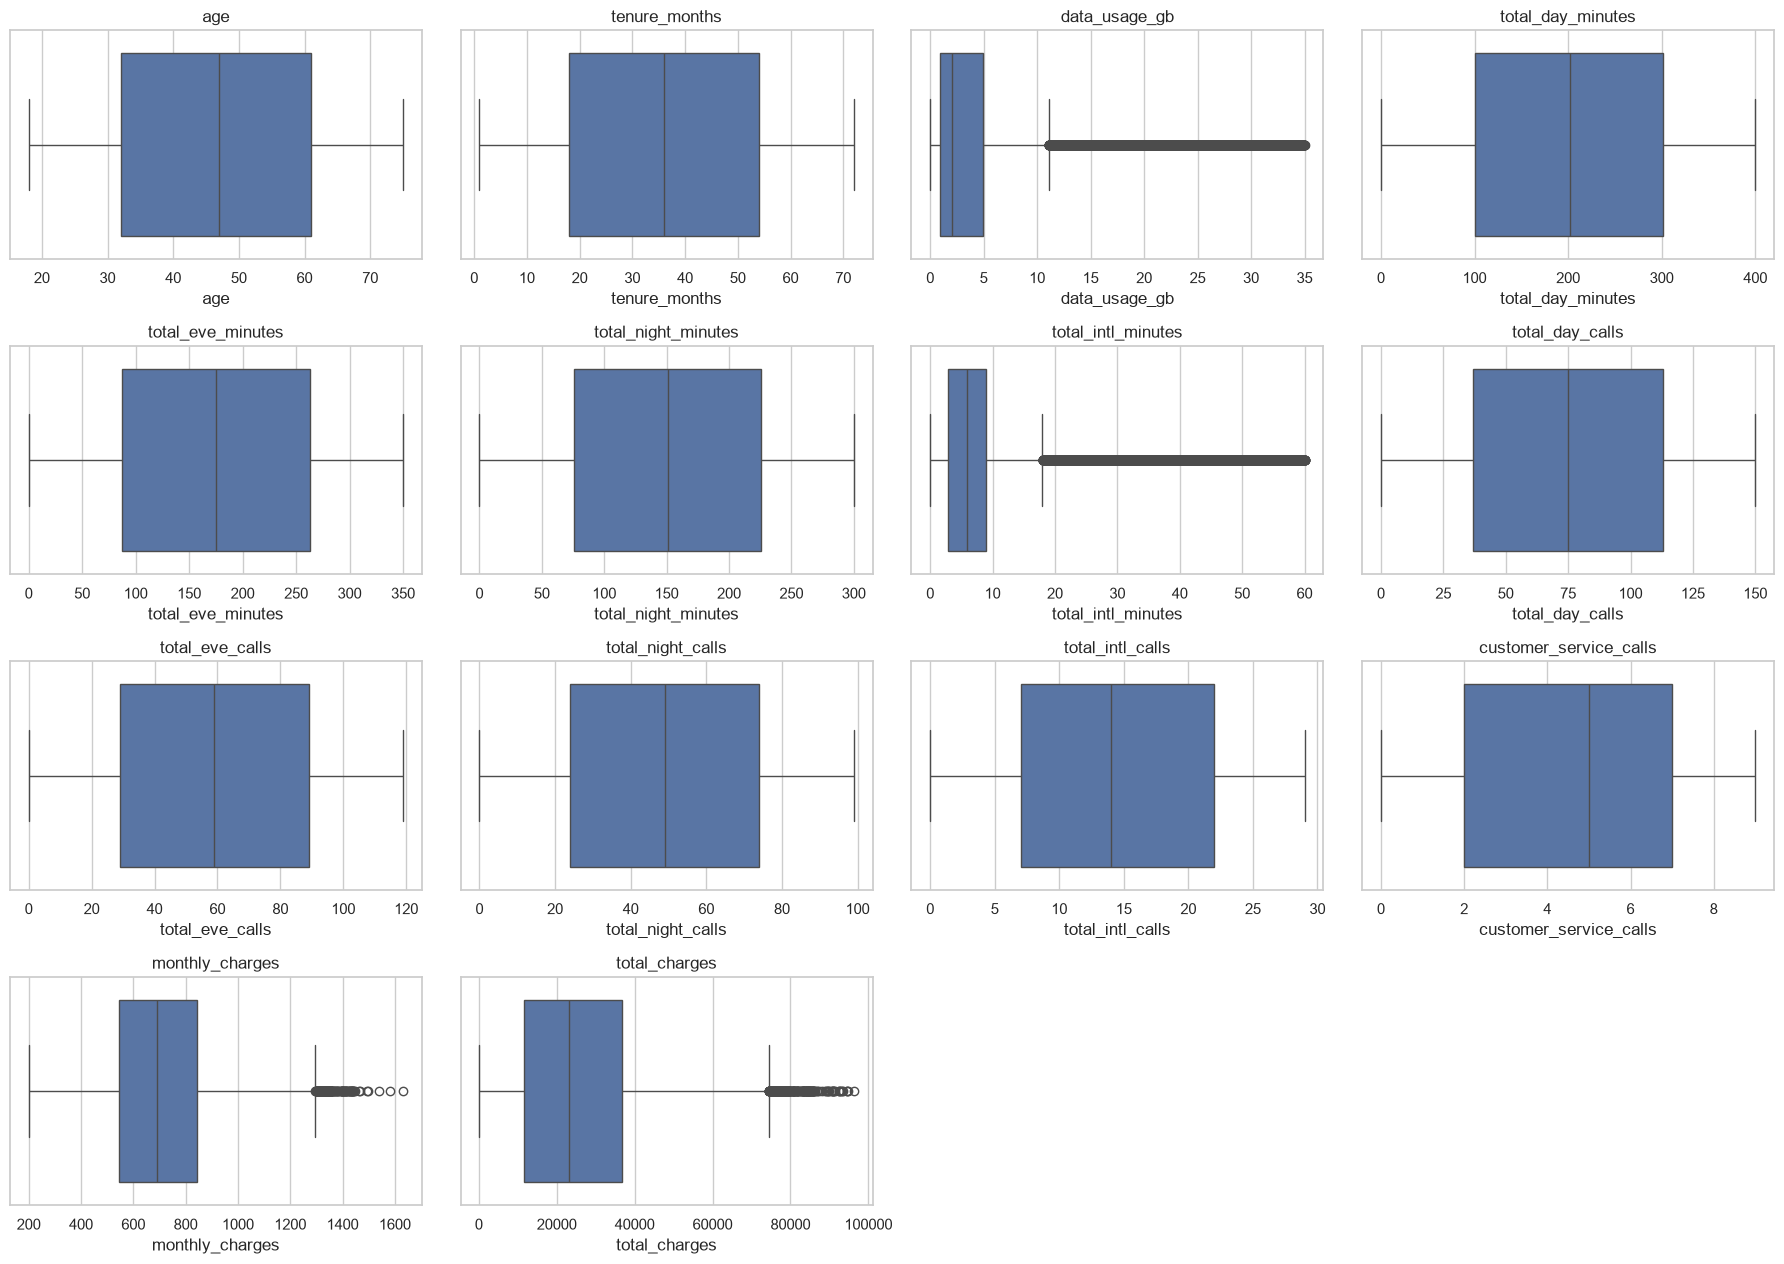

In [17]:
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.2 * nrows))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Univariate analysis – categorical

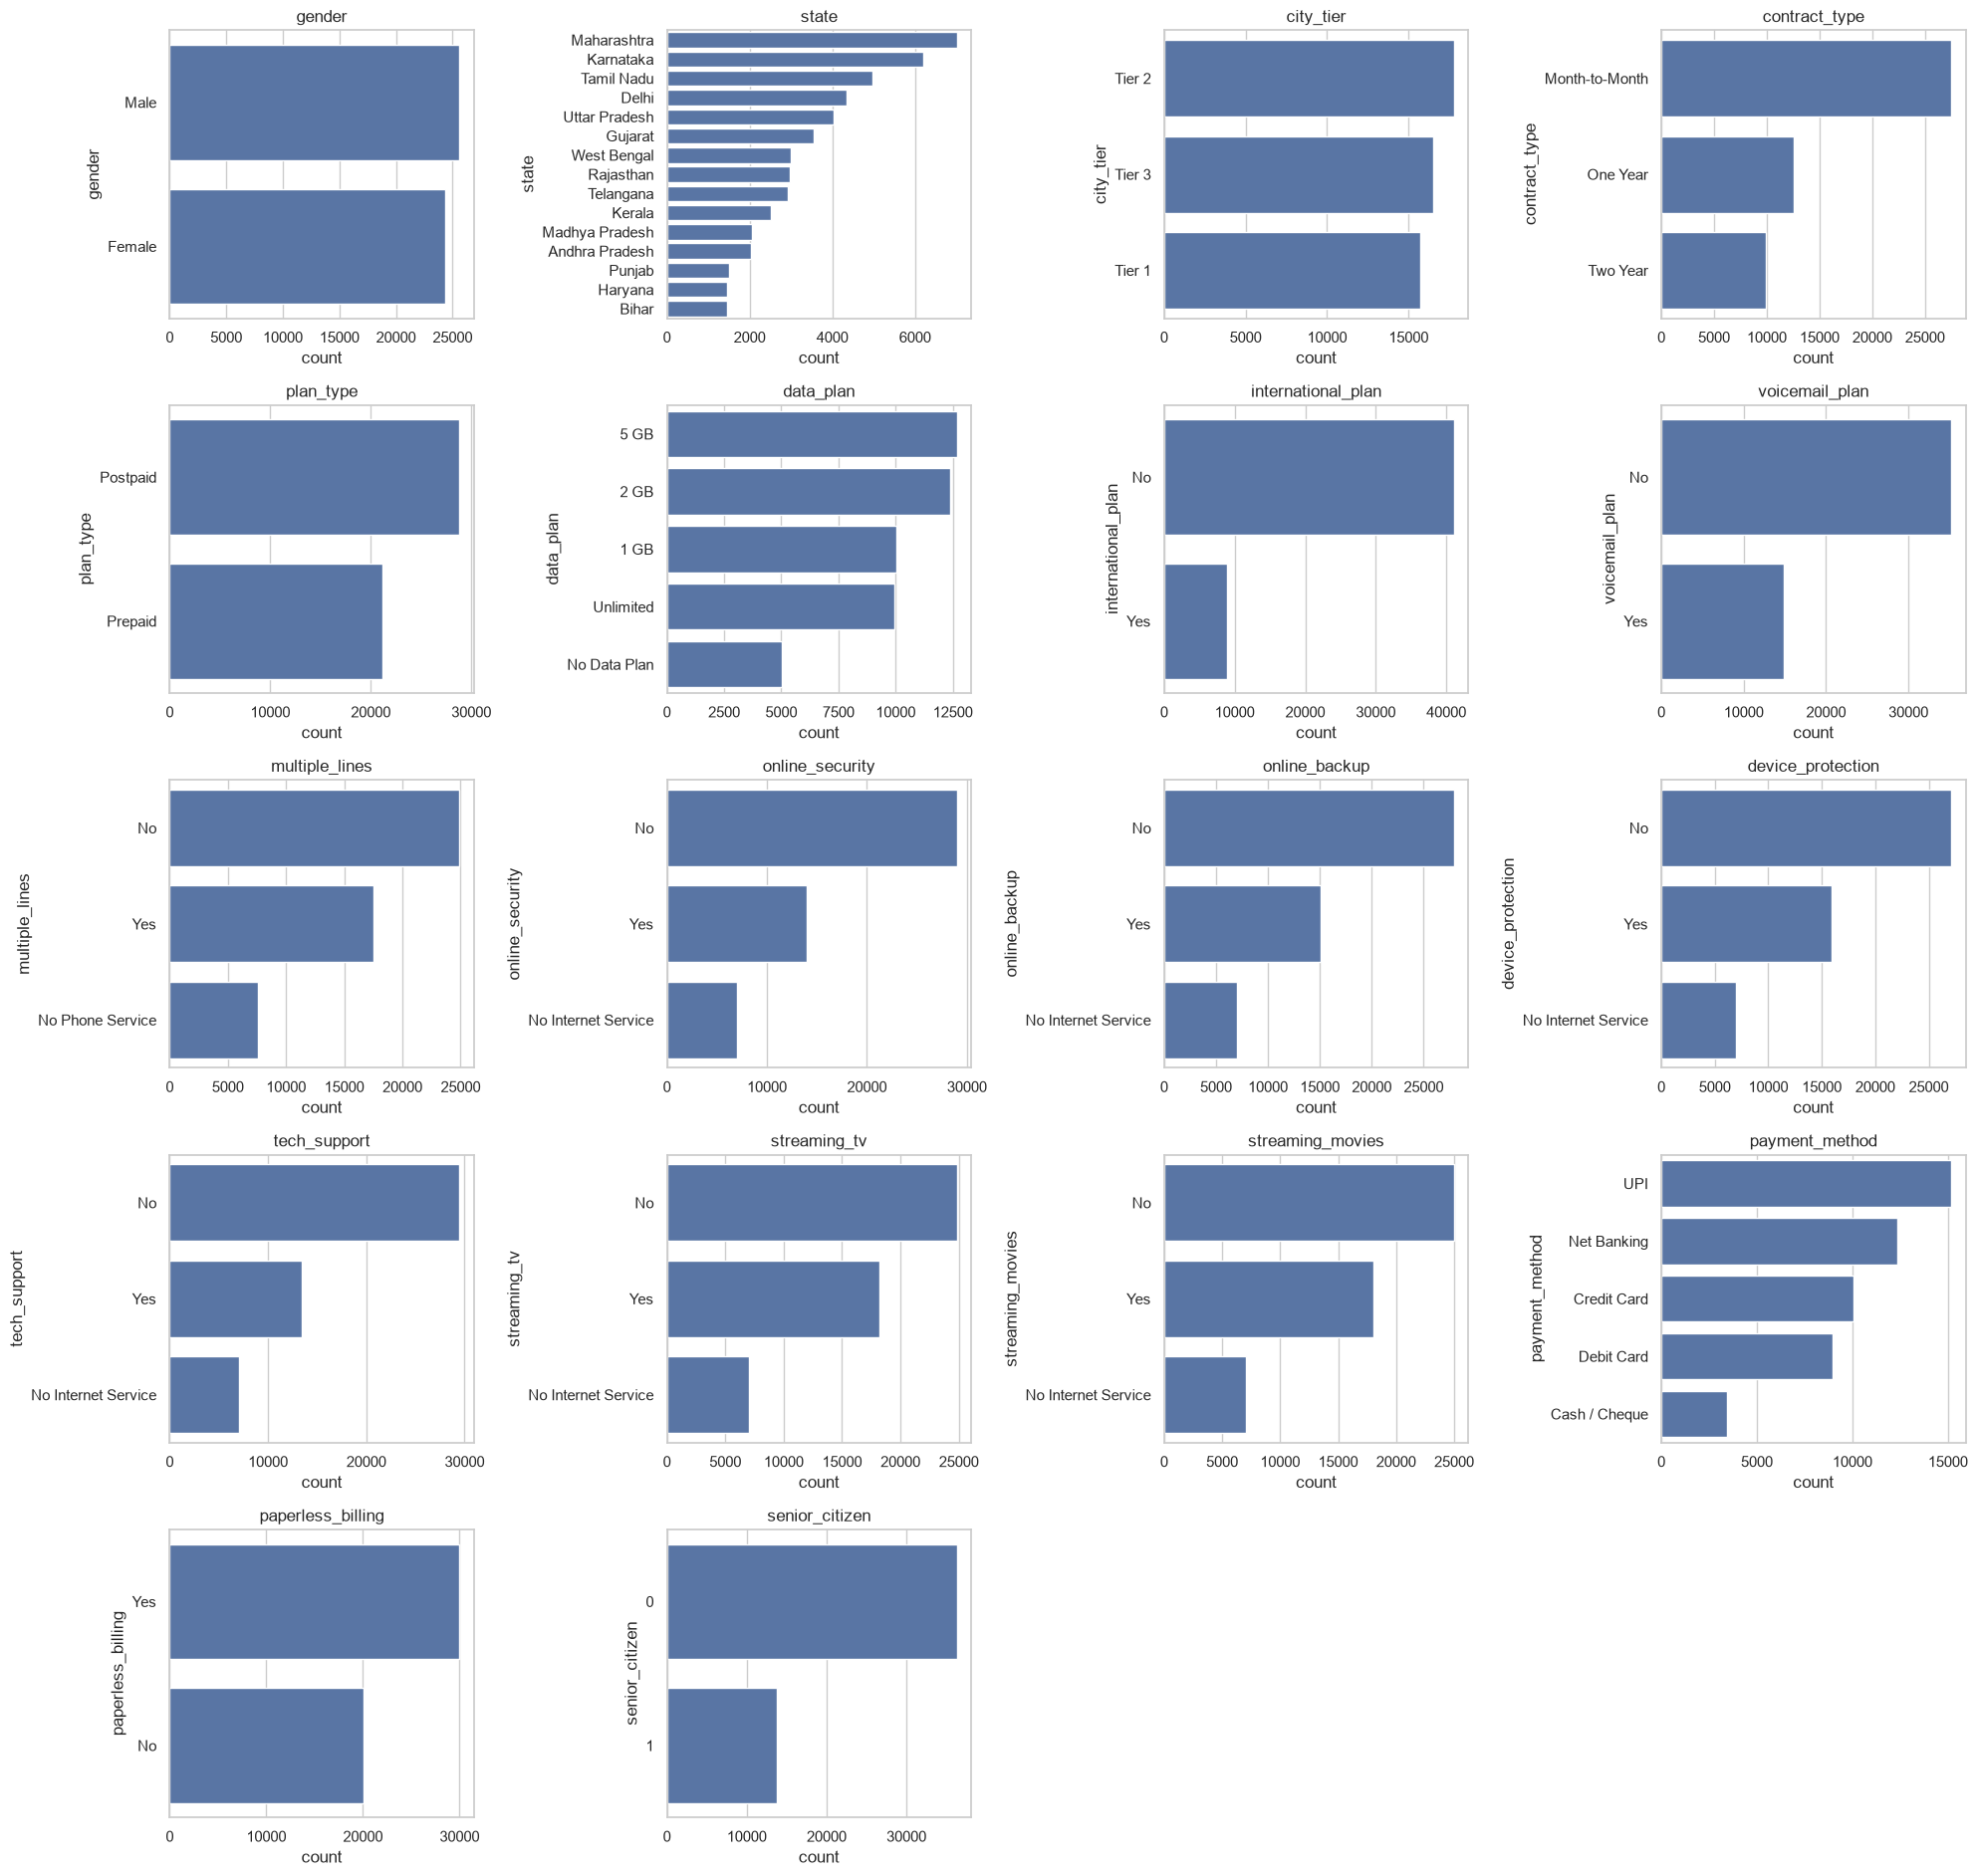

In [18]:
nrows_c = int(np.ceil(len(cat_cols) / ncols))
fig, axes = plt.subplots(nrows_c, ncols, figsize=(20, 3.8 * nrows_c))
for ax, c in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df, y=c, order=df[c].value_counts().index, ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Churn vs categorical features

In [19]:
spread = {}
for c in cat_cols:
    g = df.groupby(c)["churn_flag"].mean()
    spread[c] = g.max() - g.min()
spread = pd.Series(spread).sort_values(ascending=False)
spread.to_frame("churn_rate_spread (max-min)").round(4)

,churn_rate_spread (max-min)
contract_type,0.3952
payment_method,0.1201
online_security,0.1064
plan_type,0.0785
tech_support,0.0706
senior_citizen,0.0656
international_plan,0.0649
streaming_movies,0.0393
voicemail_plan,0.0338
streaming_tv,0.0312


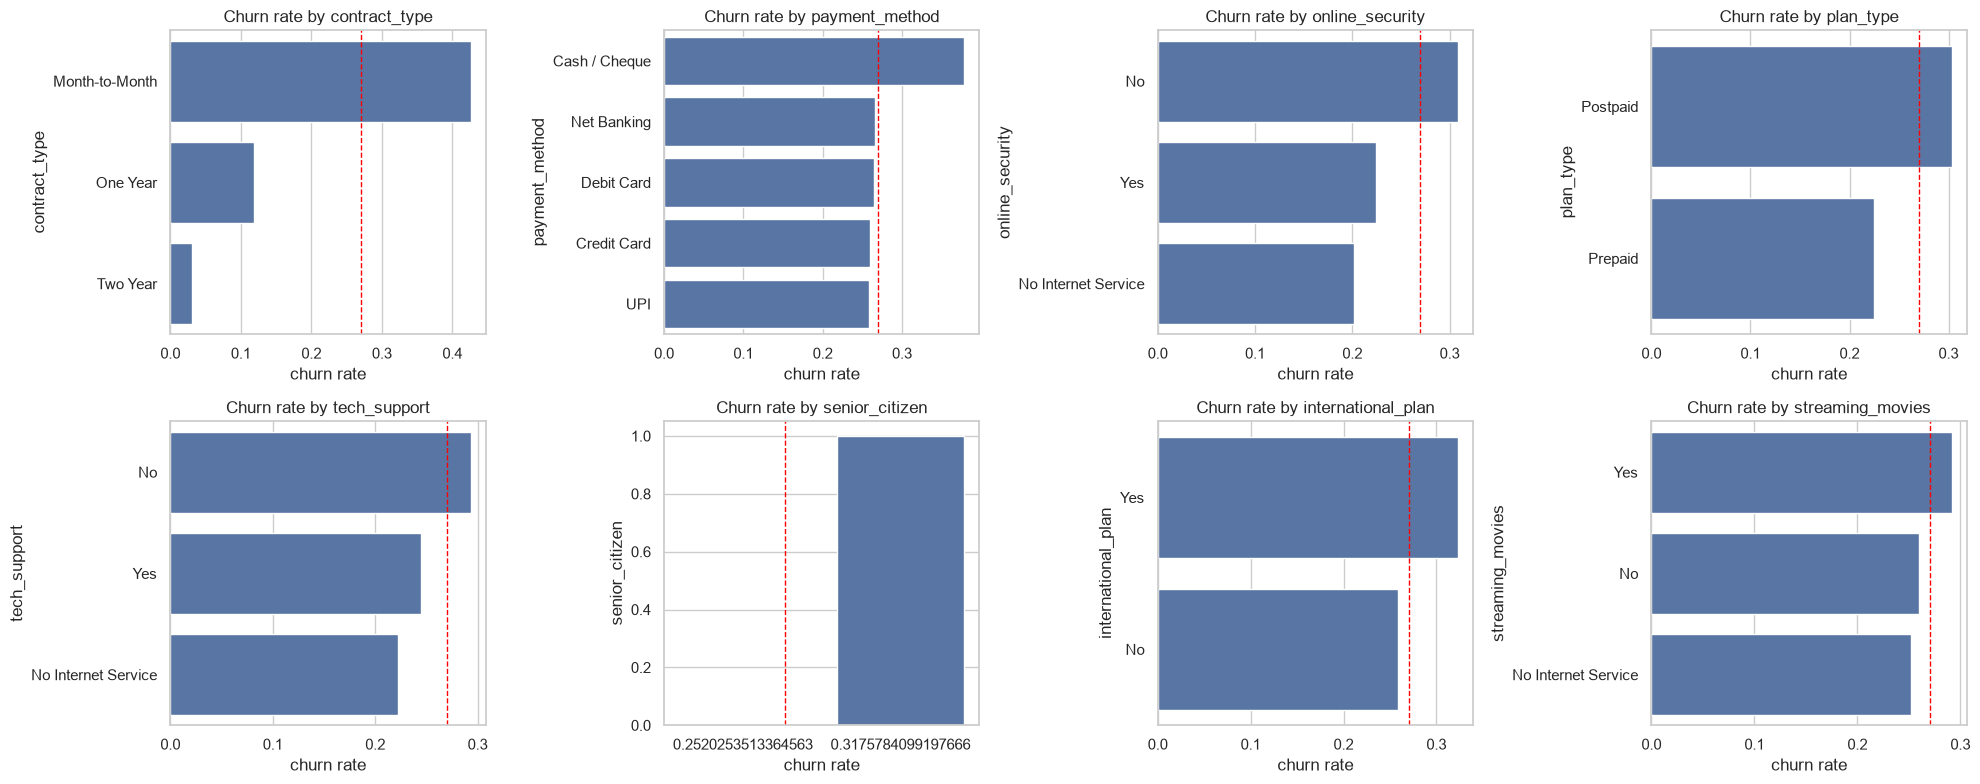

In [20]:
top_cats = spread.head(8).index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), top_cats):
    rates = df.groupby(c)["churn_flag"].mean().sort_values(ascending=False)
    sns.barplot(x=rates.values, y=rates.index, ax=ax)
    ax.axvline(churn_rate, color="red", ls="--", lw=1)
    ax.set_title(f"Churn rate by {c}")
    ax.set_xlabel("churn rate")
plt.tight_layout(); plt.show()

In [21]:
# Detailed churn rate tables for every categorical feature
for c in cat_cols:
    display(df.groupby(c)["churn_flag"].agg(churn_rate="mean", customers="count")
              .sort_values("churn_rate", ascending=False).round(4))

,churn_rate,customers
gender,,
Male,0.2745,25608
Female,0.2653,24392


,churn_rate,customers
state,,
Gujarat,0.2839,3558
Bihar,0.2802,1442
Andhra Pradesh,0.2790,2036
Madhya Pradesh,0.2768,2045
Delhi,0.2750,4335
Tamil Nadu,0.2742,4974
West Bengal,0.2710,3000
Uttar Pradesh,0.2702,4026
Maharashtra,0.2700,7005


,churn_rate,customers
city_tier,,
Tier 3,0.2726,16530
Tier 1,0.2701,15692
Tier 2,0.2675,17778


,churn_rate,customers
contract_type,,
Month-to-Month,0.4259,27475
One Year,0.1187,12571
Two Year,0.0307,9954


,churn_rate,customers
plan_type,,
Postpaid,0.3032,28819
Prepaid,0.2248,21181


,churn_rate,customers
data_plan,,
No Data Plan,0.2744,5003
Unlimited,0.2713,9922
2 GB,0.2705,12386
1 GB,0.2687,10023
5 GB,0.2678,12666


... (8 outputs left out)

,churn_rate,customers
streaming_movies,,
Yes,0.2916,18003
No,0.2594,24981
No Internet Service,0.2523,7016


,churn_rate,customers
payment_method,,
Cash / Cheque,0.3786,3447
Net Banking,0.2657,12374
Debit Card,0.2649,8955
Credit Card,0.2600,10059
UPI,0.2585,15165


,churn_rate,customers
paperless_billing,,
Yes,0.2712,29988
No,0.2682,20012


,churn_rate,customers
senior_citizen,,
1,0.3176,13710
0,0.2520,36290


In [22]:
# Chi-square test of independence (churn vs each categorical feature)
chi = {c: chi2_contingency(pd.crosstab(df[c], df["churn"]))[1] for c in cat_cols}
pd.Series(chi).sort_values().to_frame("p_value")

,p_value
contract_type,0.000000e+00
online_security,1.788296e-116
plan_type,7.902132e-85
senior_citizen,4.952874e-49
payment_method,2.720582e-47
tech_support,1.449539e-45
international_plan,7.502334e-36
streaming_movies,1.908269e-15
voicemail_plan,7.677442e-15
streaming_tv,2.056334e-12


## 7. Churn vs numeric features

In [23]:
df.groupby("churn")[num_cols].mean().T.round(2)

churn,No,Yes
age,46.00,48.00
tenure_months,40.37,25.69
data_usage_gb,5.25,5.20
total_day_minutes,200.91,200.74
total_eve_minutes,175.14,174.99
total_night_minutes,150.55,150.72
total_intl_minutes,9.18,10.32
total_day_calls,74.89,74.58
total_eve_calls,59.25,59.33
total_night_calls,49.37,49.27


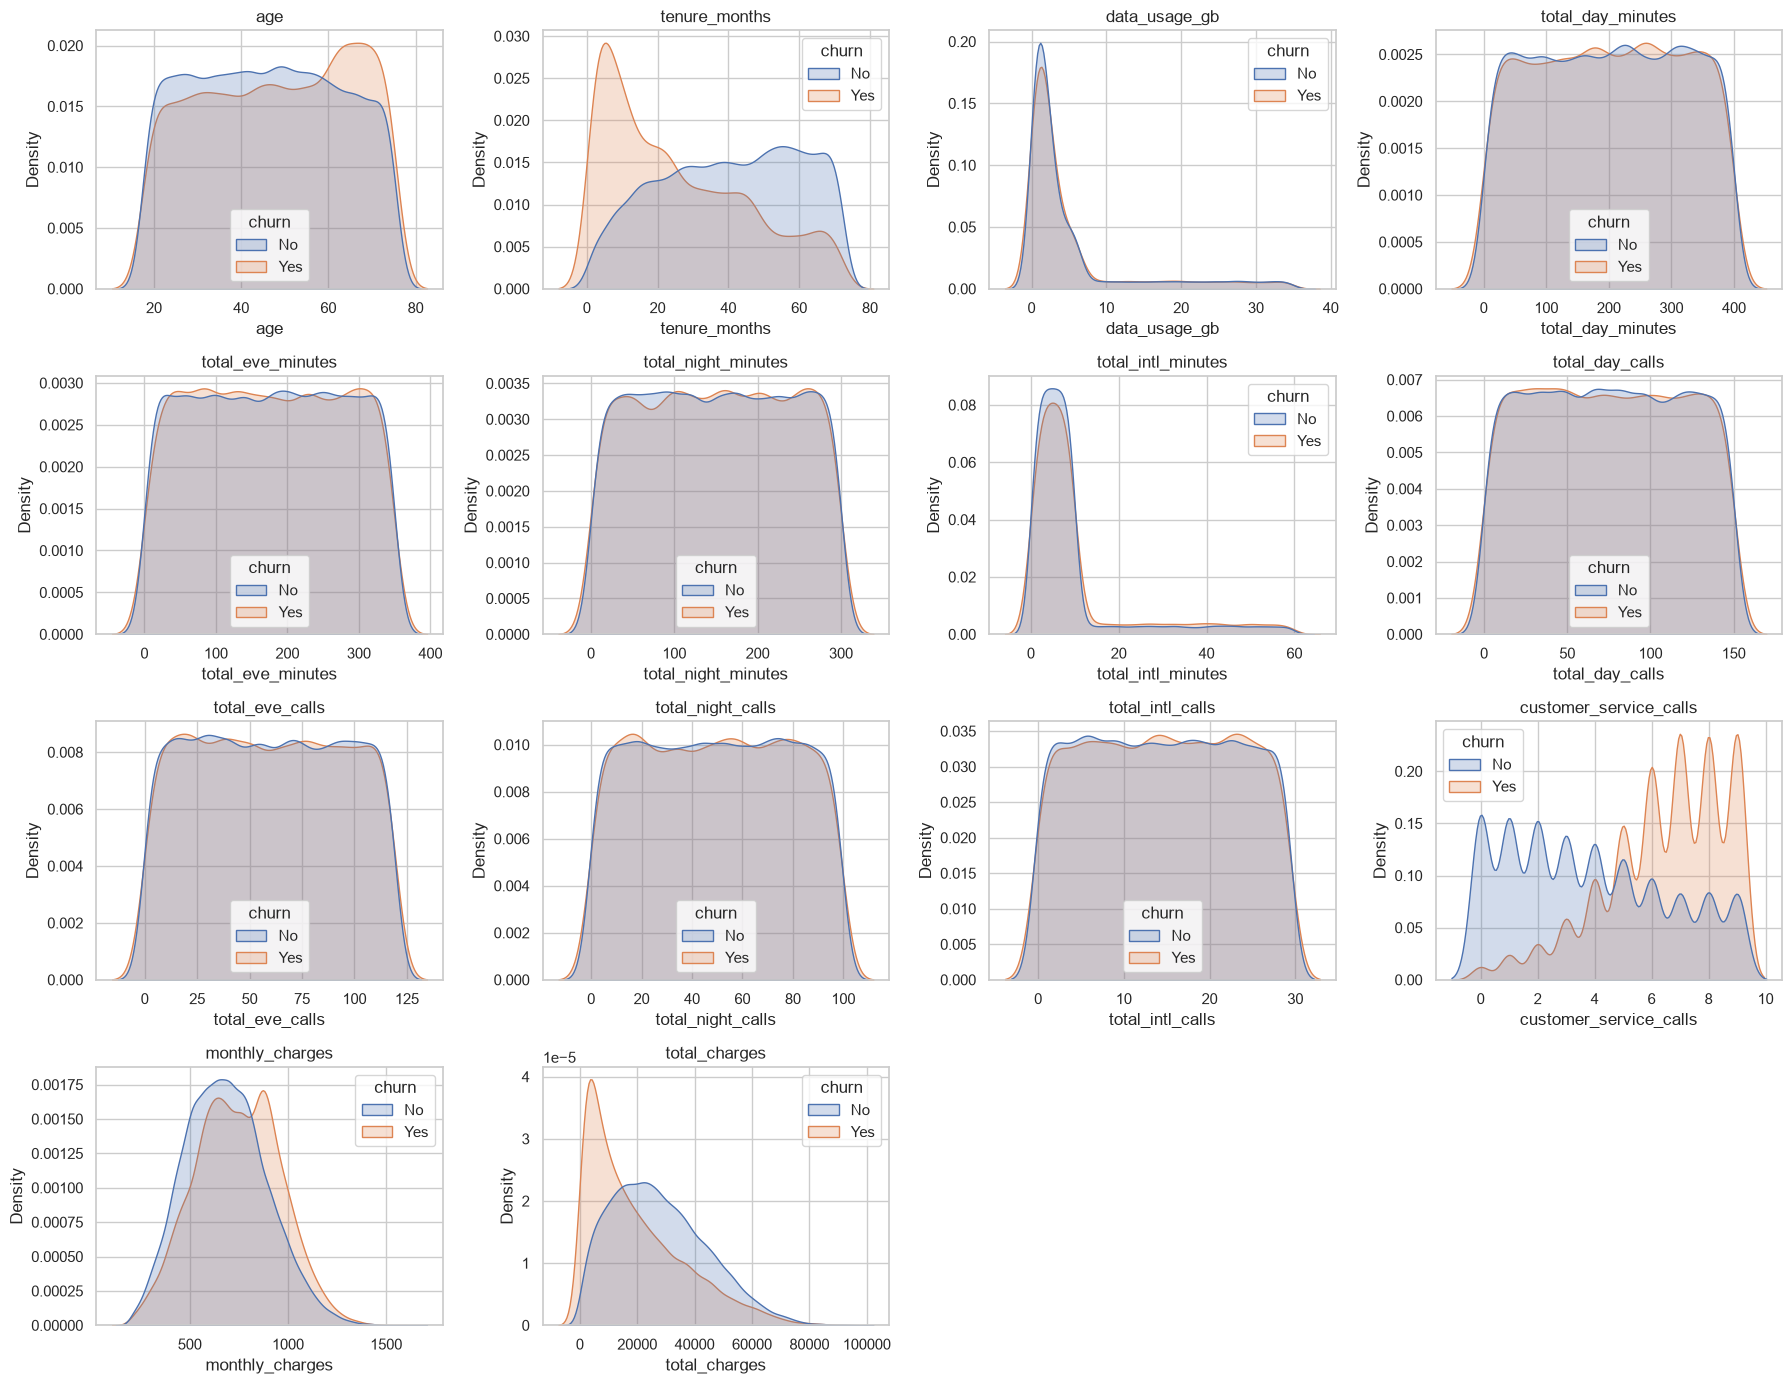

In [24]:
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.5 * nrows))
for ax, c in zip(axes.ravel(), num_cols):
    sns.kdeplot(data=df, x=c, hue="churn", common_norm=False, fill=True, ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

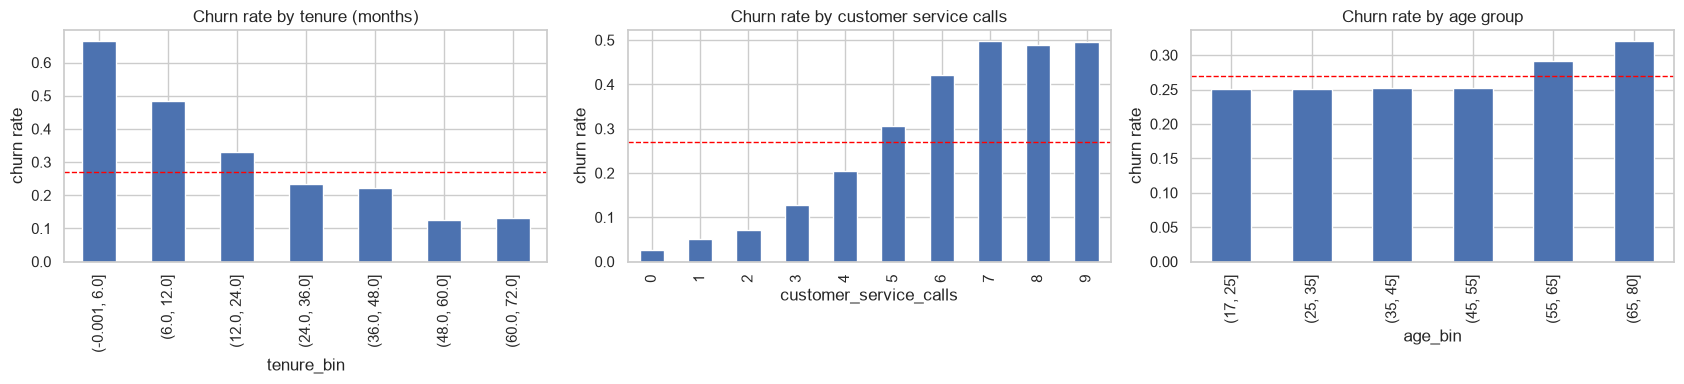

In [25]:
df["tenure_bin"] = pd.cut(df["tenure_months"], bins=[0, 6, 12, 24, 36, 48, 60, 72], include_lowest=True)
df["age_bin"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 55, 65, 80])

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
df.groupby("tenure_bin")["churn_flag"].mean().plot(kind="bar", ax=axes[0], title="Churn rate by tenure (months)")
df.groupby("customer_service_calls")["churn_flag"].mean().plot(kind="bar", ax=axes[1], title="Churn rate by customer service calls")
df.groupby("age_bin")["churn_flag"].mean().plot(kind="bar", ax=axes[2], title="Churn rate by age group")
for ax in axes:
    ax.axhline(churn_rate, color="red", ls="--", lw=1)
    ax.set_ylabel("churn rate")
plt.tight_layout(); plt.show()

## 8. Correlation analysis

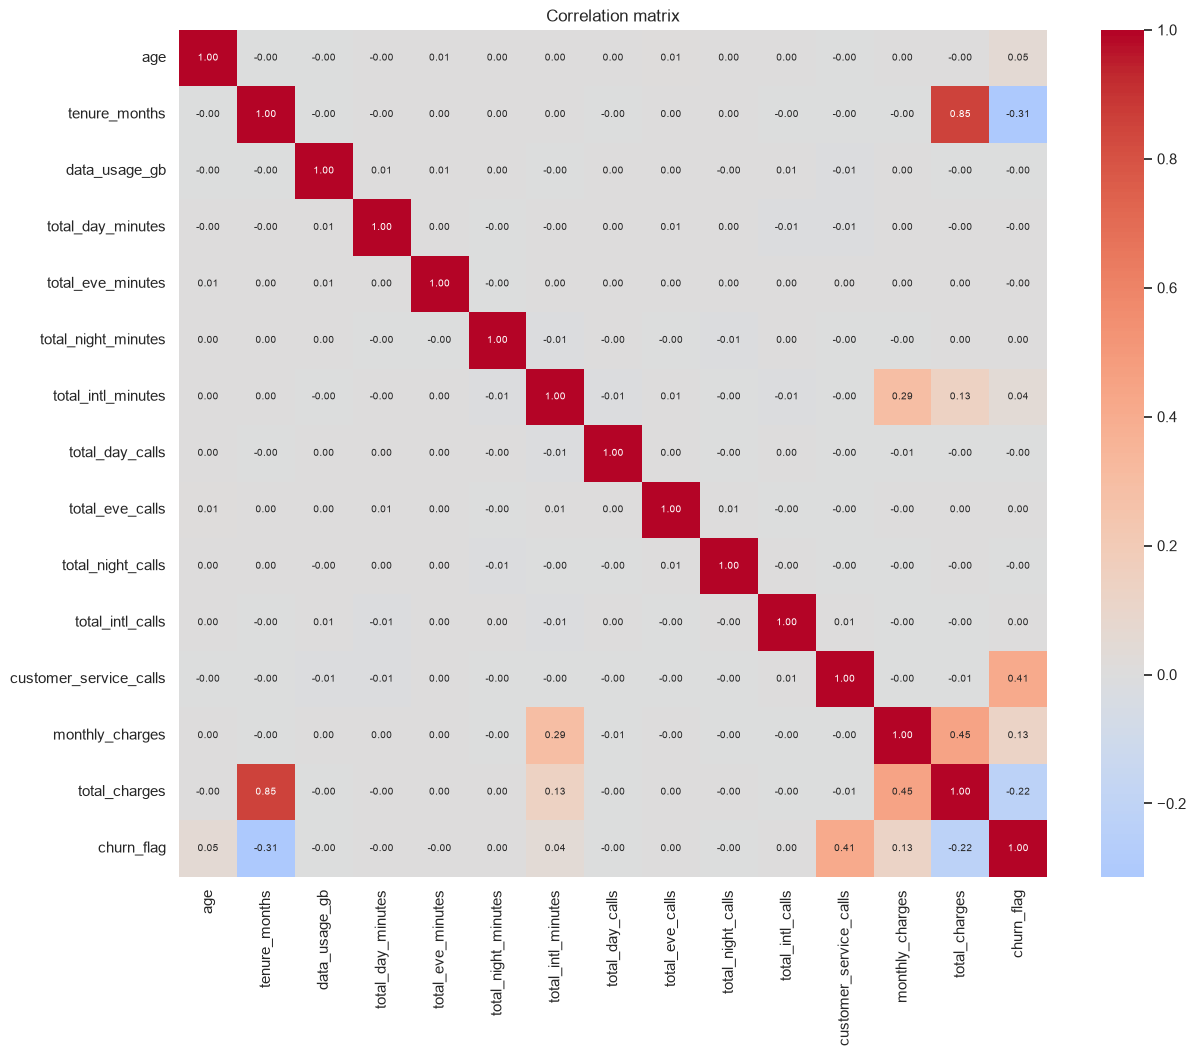

In [26]:
corr = df[num_cols + ["churn_flag"]].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix")
plt.show()

In [27]:
corr["churn_flag"].drop("churn_flag").sort_values(key=abs, ascending=False).to_frame("corr_with_churn").round(3)

,corr_with_churn
customer_service_calls,0.408
tenure_months,-0.314
total_charges,-0.217
monthly_charges,0.126
age,0.053
total_intl_minutes,0.041
total_intl_calls,0.004
total_day_calls,-0.003
data_usage_gb,-0.002
total_night_calls,-0.002


In [28]:
# Multicollinearity check
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("corr").reset_index())
pairs = pairs[(pairs["corr"].abs() > 0.7) & (pairs["level_0"] != "churn_flag") & (pairs["level_1"] != "churn_flag")]
pairs.sort_values("corr", key=abs, ascending=False)

,level_0,level_1,corr
28,tenure_months,total_charges,0.854719


## 9. Multivariate views

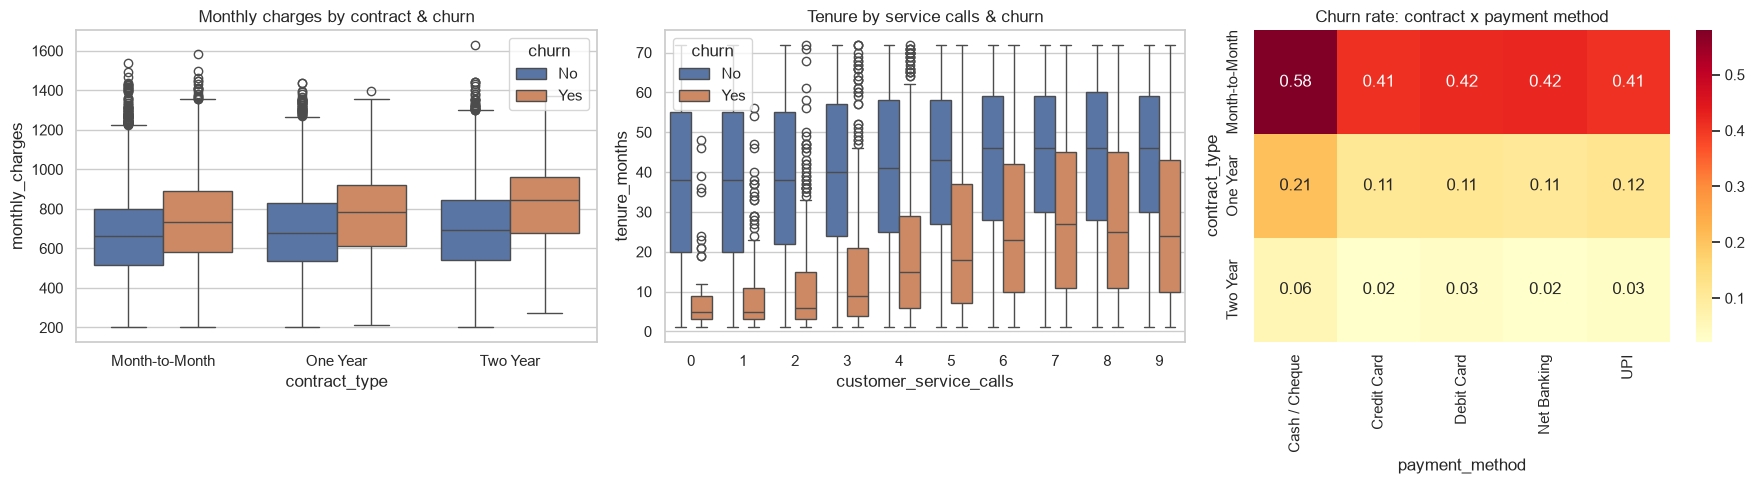

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x="contract_type", y="monthly_charges", hue="churn", ax=axes[0])
axes[0].set_title("Monthly charges by contract & churn")
sns.boxplot(data=df, x="customer_service_calls", y="tenure_months", hue="churn", ax=axes[1])
axes[1].set_title("Tenure by service calls & churn")
pv = df.pivot_table(index="contract_type", columns="payment_method", values="churn_flag", aggfunc="mean")
sns.heatmap(pv, annot=True, fmt=".2f", cmap="YlOrRd", ax=axes[2])
axes[2].set_title("Churn rate: contract x payment method")
plt.tight_layout(); plt.show()

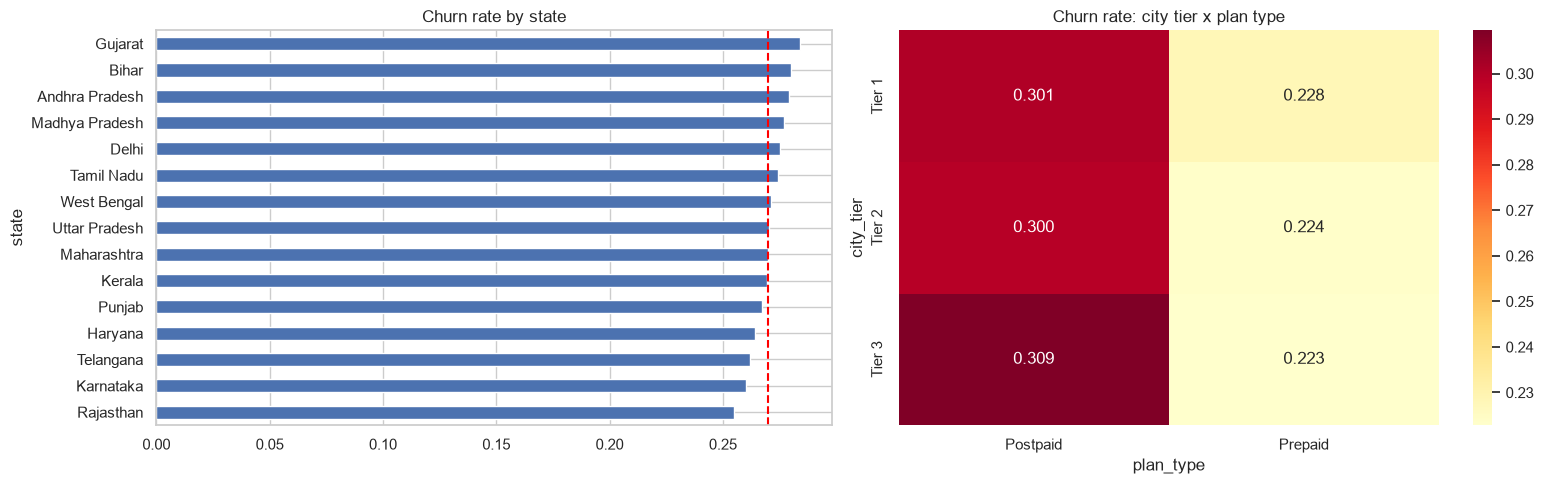

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
df.groupby("state")["churn_flag"].mean().sort_values().plot(kind="barh", ax=axes[0], title="Churn rate by state")
axes[0].axvline(churn_rate, color="red", ls="--")
pv = df.pivot_table(index="city_tier", columns="plan_type", values="churn_flag", aggfunc="mean")
sns.heatmap(pv, annot=True, fmt=".3f", cmap="YlOrRd", ax=axes[1])
axes[1].set_title("Churn rate: city tier x plan type")
plt.tight_layout(); plt.show()

## 10. Feature engineering – quick signal check

In [31]:
df["total_minutes"] = df[["total_day_minutes", "total_eve_minutes", "total_night_minutes", "total_intl_minutes"]].sum(axis=1)
df["total_calls"] = df[["total_day_calls", "total_eve_calls", "total_night_calls", "total_intl_calls"]].sum(axis=1)
df["avg_call_len"] = df["total_minutes"] / df["total_calls"].replace(0, np.nan)
df["charge_per_tenure"] = df["total_charges"] / df["tenure_months"].replace(0, np.nan)
addons = ["online_security", "online_backup", "device_protection", "tech_support", "streaming_tv", "streaming_movies"]
df["num_addons"] = (df[addons] == "Yes").sum(axis=1)

new_feats = ["total_minutes", "total_calls", "avg_call_len", "charge_per_tenure", "num_addons"]
df[new_feats + ["churn_flag"]].corr()["churn_flag"].drop("churn_flag").round(3).to_frame("corr_with_churn")

,corr_with_churn
total_minutes,0.002
total_calls,-0.002
avg_call_len,0.005
charge_per_tenure,0.126
num_addons,0.003


## 11. Mutual information (non-linear + categorical signal)

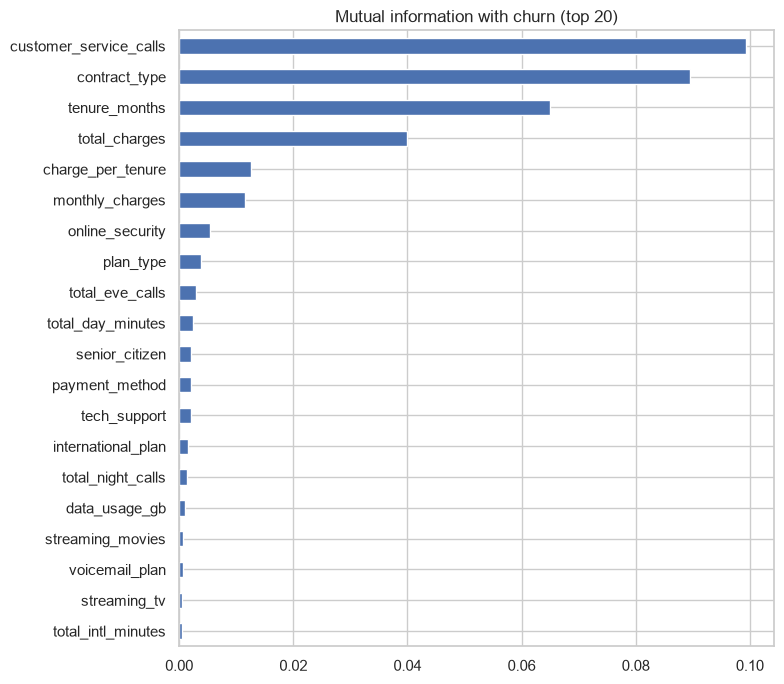

In [32]:
X = df.drop(columns=["customer_id", "churn", "churn_flag", "tenure_bin", "age_bin", "charge_gap"]).copy()
for c in X.select_dtypes(exclude="number").columns:
    X[c] = X[c].astype("category").cat.codes
discrete = [X.columns.get_loc(c) for c in cat_cols if c in X.columns]
mi = pd.Series(mutual_info_classif(X, df["churn_flag"], discrete_features=discrete, random_state=42),
               index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 7))
mi.head(20).sort_values().plot(kind="barh")
plt.title("Mutual information with churn (top 20)")
plt.tight_layout(); plt.show()

## 12. Key findings
- **Churn rate:** 27% (13,500 / 50,000) – moderately imbalanced; use stratified splits and PR-AUC / recall.
- **Data quality:** no missing values or duplicates; `total_charges` ≈ `tenure × monthly_charges`.
- **Strongest drivers:** `customer_service_calls` (r = 0.41), `contract_type` (Month-to-Month 42.6% vs Two Year 3.1%), `tenure_months` (r = −0.31).
- **Higher-churn segments:** Cash/Cheque payers, senior citizens, postpaid, international plan, no online security.
- **Little/no signal:** gender, city tier, state, data plan, paperless billing, multiple lines, day/eve/night minutes & calls.
- **Multicollinearity:** `tenure_months` vs `total_charges` (r ≈ 0.85).
- **Skew:** `data_usage_gb` and `total_intl_minutes` are right-skewed – consider log transform.
- **Next step:** tree-based models (XGBoost / LightGBM) with class weights.